# Fortune 1000 — End-to-End Data Analysis

## Problem Statement

The Fortune 1000 dataset contains financial and organisational data for the 1000 largest US companies by revenue. Each row represents one company and captures revenue, profit, employee count, sector, headquarters location, and several categorical flags.

**Business questions a data analyst could answer using this dataset:**
- Which sectors generate the highest average revenue and profit margins?
- Which US states concentrate the most Fortune 1000 headquarters?
- Do larger companies (by employee count) consistently earn higher profits?
- Which companies are outliers — generating far more revenue or profit than their peers?
- What separates profitable companies from unprofitable ones?

**Machine learning framing:**  
A natural prediction target is the `profitable` column — whether a company ends the year in profit or loss. This is a **supervised, binary classification** problem. Features would include revenue, sector, employee count, rank, and rank change. Alternatively, predicting the actual `profit` value is a **supervised regression** problem. There is no strong case for unsupervised learning here because labels exist and the business question is clearly predictive.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import gaussian_kde

print("Libraries loaded")

Libraries loaded


In [2]:
class FortuneDataset:

    def __init__(self) -> None:
        self.df: pd.DataFrame = pd.DataFrame()

    def load(self, path: str) -> pd.DataFrame:
        try:
            if path.endswith(".xlsx") or path.endswith(".xls"):
                self.df = pd.read_excel(path)
            else:
                self.df = pd.read_csv(path)
        except FileNotFoundError:
            raise FileNotFoundError(f"Dataset not found at path: {path}")
        return self.df

    def describe(self) -> None:
        print(f"Shape      : {self.df.shape}")
        print(f"\nData Types :\n{self.df.dtypes}")
        print(f"\nNull Counts:\n{self.df.isnull().sum()}")

    def split(self, test_size: float = 0.2) -> tuple[pd.DataFrame, pd.DataFrame]:
        n = len(self.df)
        test_n = int(n * test_size)
        train_indices = list(range(0, n - test_n))
        test_indices = list(range(n - test_n, n))
        return self.df.iloc[train_indices], self.df.iloc[test_indices]


ds = FortuneDataset()
df = ds.load("fortune_1000.xlsx")

# Market Cap column contains '-' for missing values — convert to numeric
df["Market Cap"] = pd.to_numeric(df["Market Cap"], errors="coerce")

ds.describe()

Shape      : (1000, 18)

Data Types :
company                  str
rank                   int64
rank_change            int64
revenue              float64
profit               float64
num. of employees    float64
sector                   str
city                     str
state                    str
newcomer                 str
ceo_founder              str
ceo_woman                str
profitable               str
prev_rank            float64
CEO                      str
Website                  str
Ticker                   str
Market Cap           float64
dtype: object

Null Counts:
company                0
rank                   0
rank_change            0
revenue                0
profit                 3
num. of employees      1
sector                 0
city                   0
state                  0
newcomer               0
ceo_founder            0
ceo_woman              0
profitable             0
prev_rank            531
CEO                    5
Website                0
Ticker      

In [3]:
numeric_cols = [col for col in df.columns if df[col].dtype in ["int64", "float64"]]
categorical_cols = [col for col in df.columns if df[col].dtype == "object"]

print("Numeric columns   :", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns   : ['rank', 'rank_change', 'revenue', 'profit', 'num. of employees', 'prev_rank', 'Market Cap']
Categorical columns: []


In [4]:
train_df, test_df = ds.split(test_size=0.2)
print(f"Train size : {len(train_df)}")
print(f"Test size  : {len(test_df)}")

Train size : 800
Test size  : 200


In [5]:
revenue = df["revenue"].to_numpy(dtype=np.float64)

rev_mean = np.mean(revenue)
rev_std  = np.std(revenue)
rev_l2   = np.linalg.norm(revenue)

print(f"Revenue Mean   : {rev_mean:,.2f}")
print(f"Revenue Std Dev: {rev_std:,.2f}")
print(f"Revenue L2 Norm: {rev_l2:,.2f}")

Revenue Mean   : 17,986.80
Revenue Std Dev: 40,792.87
Revenue L2 Norm: 1,409,816.74


In [6]:
profit_vals = df["profit"].dropna().to_numpy(dtype=np.float64)
profit_mean = np.mean(profit_vals)
profit_std  = np.std(profit_vals)

threshold = profit_mean + profit_std
profit_np = df["profit"].to_numpy(dtype=np.float64)

mask = profit_np > threshold
high_profit_companies = df[mask][["company", "profit", "sector"]]

print(f"Threshold (mean + 1 std): {threshold:,.2f}")
print(f"Companies above threshold: {len(high_profit_companies)}")
high_profit_companies.head(10)

Threshold (mean + 1 std): 8,444.83
Companies above threshold: 44


,company,profit,sector
0,Walmart,13673.0,Retailing
1,Amazon,33364.0,Retailing
2,Apple,94680.0,Technology
4,UnitedHealth Group,17285.0,Health Care
5,Exxon Mobil,23040.0,Energy
6,Berkshire Hathaway,89795.0,Financials
7,Alphabet,76033.0,Technology
12,AT&T,20081.0,Telecommunications
13,Microsoft,61271.0,Technology
15,Chevron,15625.0,Energy


In [7]:
df["profit_margin"] = (df["profit"] / df["revenue"]) * 100
print("profit_margin column added")
df[["company", "revenue", "profit", "profit_margin"]].head(5)

profit_margin column added


,company,revenue,profit,profit_margin
0,Walmart,572754.0,13673.0,2.387238
1,Amazon,469822.0,33364.0,7.101413
2,Apple,365817.0,94680.0,25.881793
3,CVS Health,292111.0,7910.0,2.707875
4,UnitedHealth Group,287597.0,17285.0,6.010146


In [8]:
sector_summary = df.groupby("sector").agg(
    avg_revenue=("revenue", "mean"),
    avg_profit_margin=("profit_margin", "mean"),
    total_employees=("num. of employees", "sum")
).reset_index().sort_values("avg_revenue", ascending=False)

sector_summary

,sector,avg_revenue,avg_profit_margin,total_employees
18,Telecommunications,58882.544444,10.765726,687640.0
7,Food & Drug Stores,49665.166667,2.942028,1334835.0
9,Health Care,34912.179221,12.849537,3384082.0
16,Retailing,30648.937662,5.976164,7868015.0
15,Motor Vehicles & Parts,23520.395000,4.712628,1046698.0
0,Aerospace & Defense,19940.117647,6.572451,857200.0
4,Energy,18845.511000,8.150704,876073.0
8,"Food, Beverages & Tobacco",18162.961765,10.727721,1122281.0
17,Technology,18050.653719,12.723839,4353295.0
6,Financials,17531.636747,17.953265,3695473.0


In [9]:
top_states = df["state"].value_counts().head(10)
top_states_df = top_states.reset_index()
top_states_df.columns = ["state", "count"]
top_states_df

,state,count
0,CA,131
1,TX,97
2,NY,87
3,IL,62
4,OH,54
5,PA,45
6,FL,38
7,GA,34
8,VA,34
9,MA,33


In [10]:
Q1 = np.percentile(revenue, 25)
Q3 = np.percentile(revenue, 75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (df["revenue"] < lower_bound) | (df["revenue"] > upper_bound)
outlier_companies = df[outlier_mask][["company", "revenue", "profit", "sector"]]

print(f"IQR        : {IQR:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}")
print(f"Upper bound: {upper_bound:,.2f}")
print(f"Outliers   : {len(outlier_companies)}")
outlier_companies

IQR        : 11,114.73
Lower bound: -13,171.34
Upper bound: 31,287.56
Outliers   : 111


,company,revenue,profit,sector
0,Walmart,572754.0,13673.0,Retailing
1,Amazon,469822.0,33364.0,Retailing
2,Apple,365817.0,94680.0,Technology
3,CVS Health,292111.0,7910.0,Health Care
4,UnitedHealth Group,287597.0,17285.0,Health Care
...,...,...,...,...
106,Qualcomm,33566.0,9043.0,Technology
107,Capital One Financial,32033.0,12390.0,Financials
108,TD Synnex,31614.2,395.1,Wholesalers
109,Philip Morris International,31405.0,9109.0,"Food, Beverages & Tobacco"


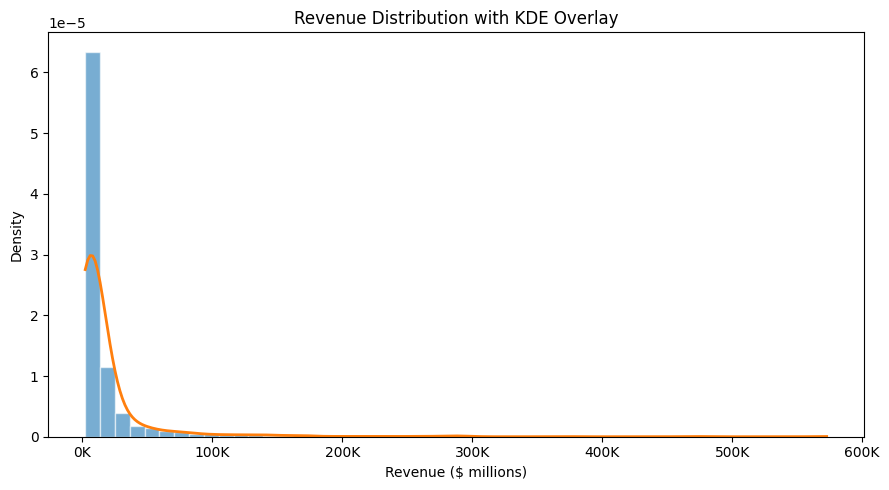

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(revenue, bins=50, density=True, alpha=0.6, edgecolor="white")

kde_x = np.linspace(revenue.min(), revenue.max(), 300)
kde = gaussian_kde(revenue)
ax.plot(kde_x, kde(kde_x), linewidth=2)

ax.set_title("Revenue Distribution with KDE Overlay")
ax.set_xlabel("Revenue ($ millions)")
ax.set_ylabel("Density")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}K"))
plt.tight_layout()
plt.show()

/tmp/ipykernel_622/2835383796.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sector_data, labels=top6_sectors, vert=True)


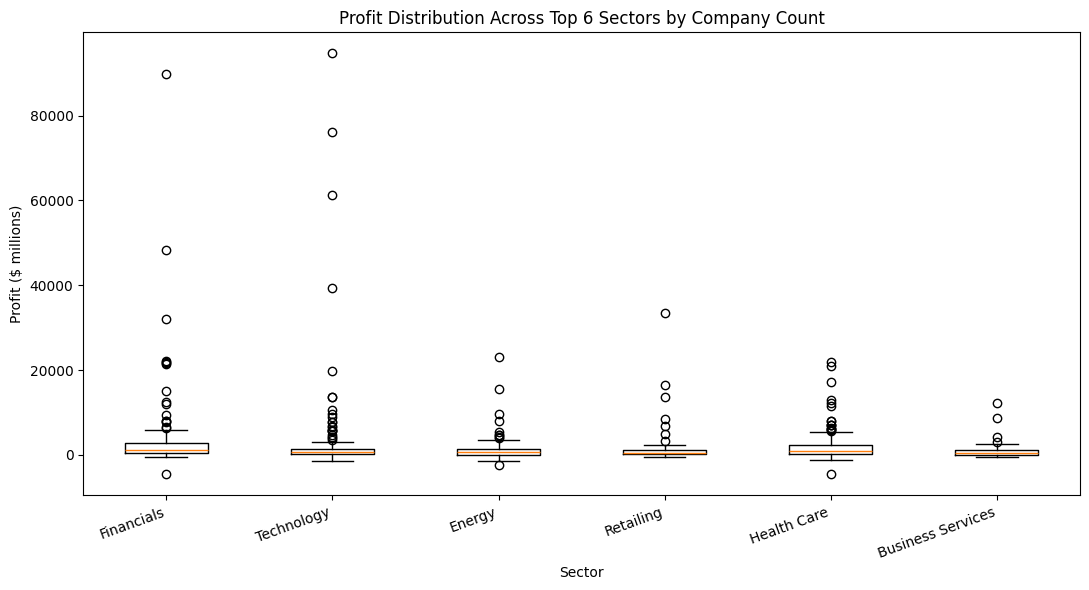

In [12]:
top6_sectors = df["sector"].value_counts().head(6).index.tolist()
df_top6 = df[df["sector"].isin(top6_sectors)].copy()

fig, ax = plt.subplots(figsize=(11, 6))

sector_data = [df_top6[df_top6["sector"] == s]["profit"].dropna().values for s in top6_sectors]
ax.boxplot(sector_data, labels=top6_sectors, vert=True)

ax.set_title("Profit Distribution Across Top 6 Sectors by Company Count")
ax.set_xlabel("Sector")
ax.set_ylabel("Profit ($ millions)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

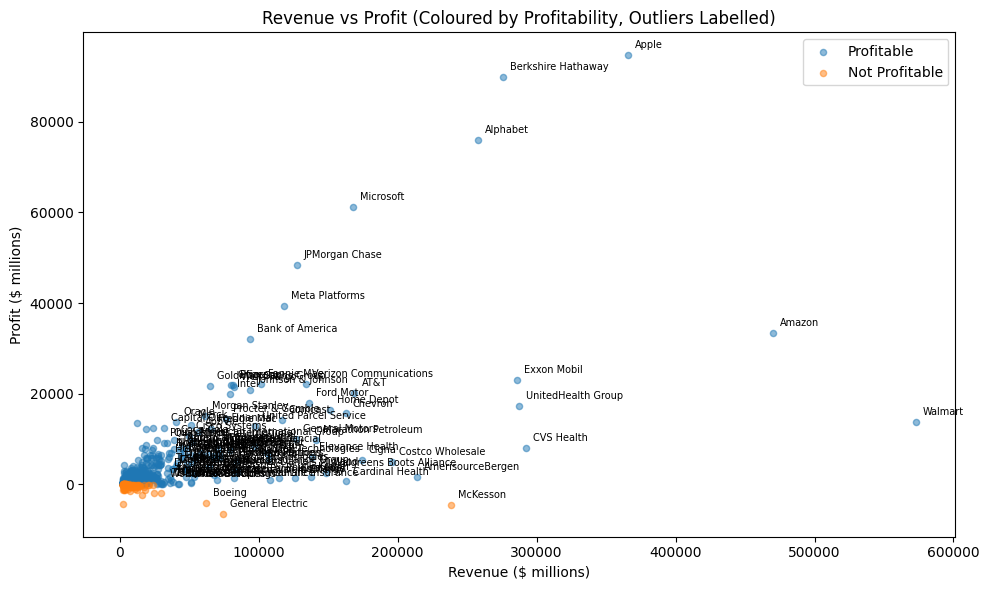

In [13]:
df_plot = df.dropna(subset=["profit"]).copy()
profitable_mask = df_plot["profitable"] == "yes"

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(df_plot[profitable_mask]["revenue"], df_plot[profitable_mask]["profit"],
           alpha=0.5, s=20, label="Profitable")
ax.scatter(df_plot[~profitable_mask]["revenue"], df_plot[~profitable_mask]["profit"],
           alpha=0.5, s=20, label="Not Profitable")

for _, row in outlier_companies.iterrows():
    if pd.notna(row["profit"]):
        ax.annotate(row["company"],
                    xy=(row["revenue"], row["profit"]),
                    fontsize=7,
                    xytext=(5, 5),
                    textcoords="offset points")

ax.set_title("Revenue vs Profit (Coloured by Profitability, Outliers Labelled)")
ax.set_xlabel("Revenue ($ millions)")
ax.set_ylabel("Profit ($ millions)")
ax.legend()
plt.tight_layout()
plt.show()

## Outlier Interpretation

The IQR method flags companies whose revenue is more than 1.5× the interquartile range above Q3. These are not errors in the data — they are the largest US corporations by revenue, companies like Walmart, Amazon, Apple, and ExxonMobil.

In business terms, these outliers represent firms operating at a fundamentally different scale from the median Fortune 1000 company. A typical company in this list earns revenues in the $3–15 billion range; the outliers reach into the hundreds of billions. Their presence skews the mean significantly upward, which is why the revenue distribution is heavily right-skewed as seen in the histogram. For machine learning, these values would likely need log-transformation to prevent them from dominating a linear model.

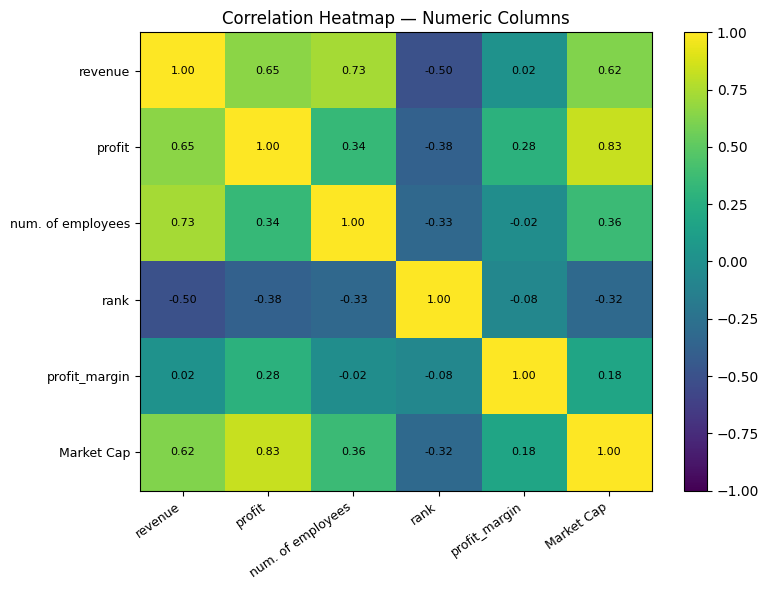

In [14]:
corr_cols = ["revenue", "profit", "num. of employees", "rank", "profit_margin", "Market Cap"]
df_corr = df[corr_cols].dropna()
corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(corr_matrix.values, aspect="auto", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax)

labels = corr_matrix.columns.tolist()
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right", fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Correlation Heatmap — Numeric Columns")
plt.tight_layout()
plt.show()

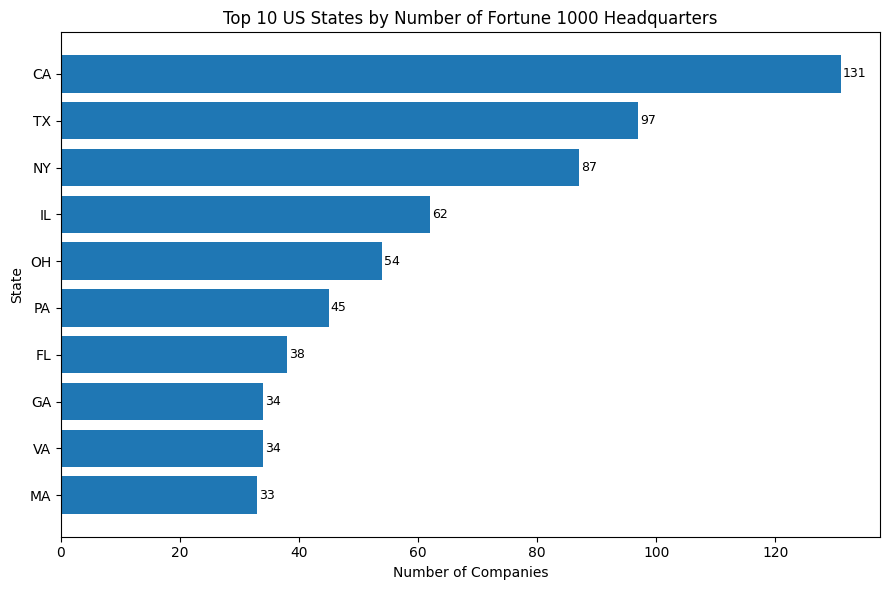

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(top_states_df["state"][::-1], top_states_df["count"][::-1])

ax.set_title("Top 10 US States by Number of Fortune 1000 Headquarters")
ax.set_xlabel("Number of Companies")
ax.set_ylabel("State")

for i, (count, state) in enumerate(zip(top_states_df["count"][::-1], top_states_df["state"][::-1])):
    ax.text(count + 0.3, i, str(count), va="center", fontsize=9)

plt.tight_layout()
plt.show()

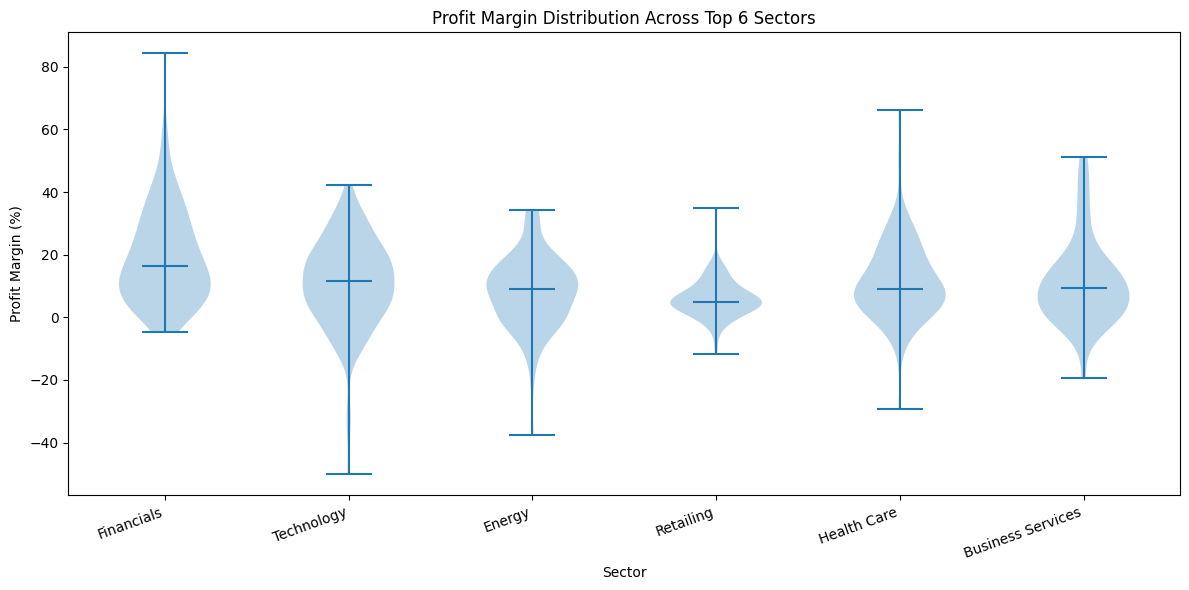

In [16]:
df_violin = df[df["sector"].isin(top6_sectors)].dropna(subset=["profit_margin"]).copy()
df_violin = df_violin[df_violin["profit_margin"].between(-100, 100)]

fig, ax = plt.subplots(figsize=(12, 6))

violin_data = [df_violin[df_violin["sector"] == s]["profit_margin"].values for s in top6_sectors]
parts = ax.violinplot(violin_data, positions=range(len(top6_sectors)), showmedians=True)

ax.set_xticks(range(len(top6_sectors)))
ax.set_xticklabels(top6_sectors, rotation=20, ha="right")
ax.set_title("Profit Margin Distribution Across Top 6 Sectors")
ax.set_xlabel("Sector")
ax.set_ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

## Summary of Key Findings

**1. Revenue is extremely concentrated at the top.**  
Most Fortune 1000 companies earn between $3 billion and $15 billion in revenue, but a small group of giants — primarily in Retailing, Technology, and Energy — operates at ten to thirty times that scale. This heavy right-skew means the average revenue figure tells you very little about the typical company in this list.

**2. Financials is the largest sector, but Technology companies earn the best margins.**  
With 166 companies, Financials dominates the list by count. However, when average profit margin is compared across sectors, Technology firms stand out — generating a higher proportion of profit from each dollar of revenue than sectors like Energy or Retailing, which require enormous revenue bases just to stay profitable.

**3. New York, California, and Texas together account for a disproportionate share of Fortune 1000 headquarters.**  
The top 10 states account for the majority of all Fortune 1000 headquarters, with the top three contributing the largest portion. This concentration reflects where financial services, technology, and energy industries are based.

**4. Revenue and Market Cap are positively correlated, but profit margin does not simply scale with company size.**  
The heatmap shows that revenue, profit, and market cap move together to a meaningful degree. However, profit margin — profit as a percentage of revenue — does not scale with size in a straightforward way. Some of the largest companies by revenue operate on razor-thin margins, while mid-size firms in certain sectors maintain high margins.

**5. A sizeable minority of Fortune 1000 companies are unprofitable.**  
The scatter plot shows unprofitable companies at every revenue level — not only among the smallest firms. Being large enough to appear on the Fortune 1000 list does not guarantee profitability. This makes the profitable/unprofitable classification problem a meaningful and non-trivial machine learning task.